# BU First Destination Survey (FDS) Analysis + Handshake Bridge + Student Outcome Analysis
**Data:** FDS_2020-2024_Employer_Outcomes_Anonymized.xlsx | 10,004 BU graduate outcomes (2019–2024)

**Contributors: Sviat Shevchenko (Track 1 FDS Analysis + Track 2 Handshake Bridge), Shaotai Hu (Track 3 Student Outcome Analysis), Abigail Merage, Tessa Thomas**

Last Updated: 3/24/2026

Documentation link: https://docs.google.com/document/d/1noKw36_t1GgOxWHFcByYh6V7X5I12J-5jIe-ArHE_l8/edit?usp=sharing

**Structure:**
- **Track 1**: Standalone FDS analysis: outcomes by college, major, industry, job function, demographics, geography, trends
- **Track 2**: Handshake bridge: compare EEIS-ranked employers vs actual BU graduate placement
- **Track 3**: Student outcome analysis: employer activity vs student hiring outcomes (Shaotai Hu)

> Note: FDS data has no employer_id so cannot be directly joined to Handshake. Track 2 uses manual name mapping for the top 20 Handshake employers. Track 3 uses a fuzzy name merge between ep_joined and outcomes.csv.

## Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# ---- File locations ----
# Update DATA_DIR to wherever your CSVs live.
DATA_DIR = ''

fds = pd.read_excel(os.path.join(DATA_DIR, 'FDS 2020-2024 Employer Outcomes (Anonymized).xlsx'))

# Clean graduation year
fds['grad_year'] = fds['Graduation Date'].str.extract(r'(\d{4})').astype(float).astype('Int64')

# Normalize gender
fds['gender_clean'] = fds['Student Gender'].replace({'Female': 'Woman', 'Male': 'Man'})

# Normalize domestic/international
fds['intl_clean'] = fds['Student Domestic/International Status'].replace({
    'Y': 'International', '?': 'Unknown'
})

# Load employer KPI from Milestone 2 output
employer_kpi = pd.read_csv(os.path.join(DATA_DIR, 'employer_kpi.csv'))

print(f'FDS rows: {len(fds):,}')
print(f'Years: {sorted(fds["grad_year"].dropna().unique().tolist())}')
print(f'employer_kpi rows: {len(employer_kpi):,}')
print(f'employer_kpi columns: {employer_kpi.columns.tolist()}')

FDS rows: 10,004
Years: [2019, 2020, 2021, 2022, 2023, 2024]
employer_kpi rows: 56,089
employer_kpi columns: ['employer_id', 'employer_name', 'employer_type', 'total_jobs', 'total_applications', 'JAY', 'total_events_dedup', 'total_attendees_dedup', 'EAY', 'EEB', 'EEC', 'ACI', 'avg_salary_mid', 'SSI', 'EEIS', 'EEIS_equal', 'EEIS_pca', 'EEIS_rank', 'rank_equal', 'rank_pca', 'rank_based', 'active_years_unified', 'years_span']


/var/folders/hv/tcqdmtjd09j4hgvm2929vjbh0000gn/T/ipykernel_9330/2357885444.py:29: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  employer_kpi = pd.read_csv(os.path.join(DATA_DIR, 'employer_kpi.csv'))


---
# Track 1: Standalone FDS Analysis
Examines BU graduate employment outcomes independently of Handshake data.

**Contributor: Sviat Shevchenko**

## 1A. Top Hiring Employers by Volume

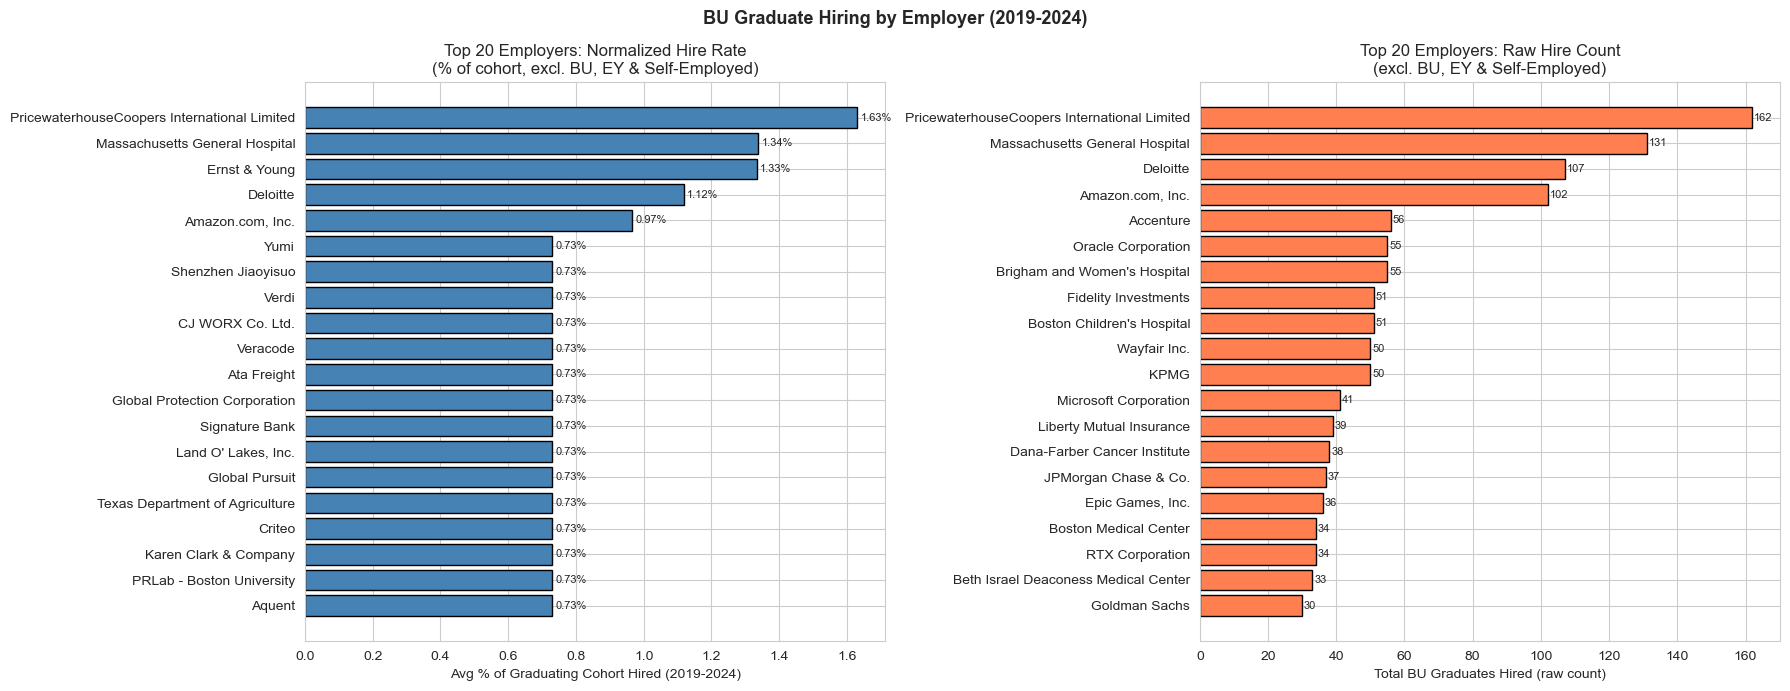

Top 20 by Normalized Hire Rate (% of cohort):
Employer Name
PricewaterhouseCoopers International Limited    1.631
Massachusetts General Hospital                  1.337
Ernst & Young                                   1.334
Deloitte                                        1.119
Amazon.com, Inc.                                0.966
Yumi                                            0.730
Shenzhen Jiaoyisuo                              0.730
Verdi                                           0.730
CJ WORX Co. Ltd.                                0.730
Veracode                                        0.730
Ata Freight                                     0.730
Global Protection Corporation                   0.730
Signature Bank                                  0.730
Land O' Lakes, Inc.                             0.730
Global Pursuit                                  0.730
Texas Department of Agriculture                 0.730
Criteo                                          0.730
Karen Clark & Company 

In [2]:
# 1A. Top Hiring Employers — Normalized by Cohort Size
# Jimmy feedback: express as % of graduating cohort, not raw counts
# Also exclude EY alongside BU for comparability

exclude = ['boston university', 'unknown', 'self-employed', 'ey']

# Cohort size per graduation year
cohort_size = fds.groupby('grad_year').size().reset_index(name='cohort_size')

# Hires per employer per year
hires_by_year = fds[
    ~fds['Employer Name'].str.lower().fillna('').isin(exclude)
].groupby(['grad_year', 'Employer Name']).size().reset_index(name='raw_hires')

hires_norm = hires_by_year.merge(cohort_size, on='grad_year')
hires_norm['hire_pct'] = hires_norm['raw_hires'] / hires_norm['cohort_size'] * 100

# Average normalized hire rate across years
top_emp_norm = hires_norm.groupby('Employer Name')['hire_pct']\
    .mean().sort_values(ascending=False).head(20)

# Raw counts for reference
top_emp_raw = fds[
    ~fds['Employer Name'].str.lower().fillna('').isin(exclude)
]['Employer Name'].value_counts().head(20)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left: normalized
axes[0].barh(top_emp_norm.index[::-1], top_emp_norm.values[::-1],
             color='steelblue', edgecolor='black')
for i, v in enumerate(top_emp_norm.values[::-1]):
    axes[0].text(v + 0.01, i, f'{v:.2f}%', va='center', fontsize=8)
axes[0].set_xlabel('Avg % of Graduating Cohort Hired (2019-2024)')
axes[0].set_title('Top 20 Employers: Normalized Hire Rate\n(% of cohort, excl. BU, EY & Self-Employed)')

# Right: raw counts for reference
axes[1].barh(top_emp_raw.index[::-1], top_emp_raw.values[::-1],
             color='coral', edgecolor='black')
for i, v in enumerate(top_emp_raw.values[::-1]):
    axes[1].text(v + 0.5, i, str(v), va='center', fontsize=8)
axes[1].set_xlabel('Total BU Graduates Hired (raw count)')
axes[1].set_title('Top 20 Employers: Raw Hire Count\n(excl. BU, EY & Self-Employed)')

plt.suptitle('BU Graduate Hiring by Employer (2019-2024)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Top 20 by Normalized Hire Rate (% of cohort):')
print(top_emp_norm.round(3))

## 1B. Outcomes by Industry

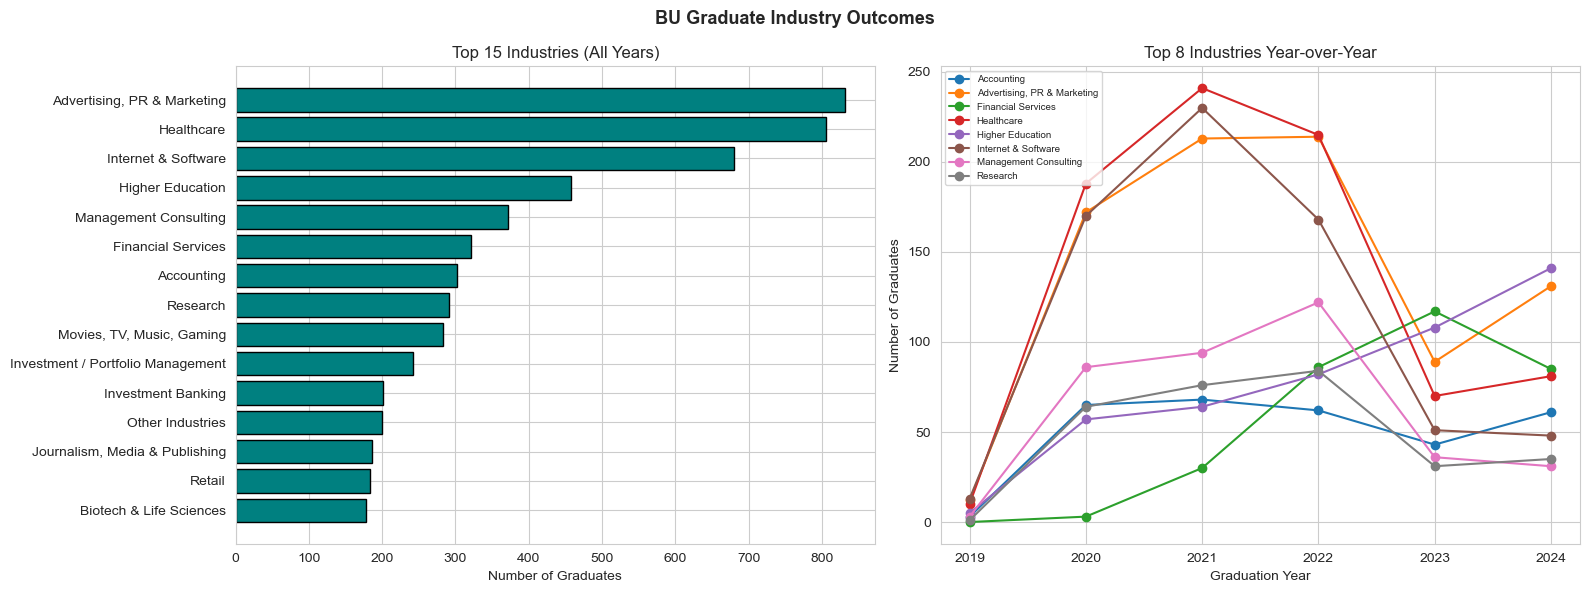

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Overall top industries
top_ind = fds['Employer Industry'].value_counts().head(15)
axes[0].barh(top_ind.index[::-1], top_ind.values[::-1], color='teal', edgecolor='black')
axes[0].set_xlabel('Number of Graduates')
axes[0].set_title('Top 15 Industries (All Years)')

# Industry by year (top 8)
top8_ind = fds['Employer Industry'].value_counts().head(8).index
ind_year = fds[fds['Employer Industry'].isin(top8_ind)]\
    .groupby(['grad_year', 'Employer Industry']).size().unstack(fill_value=0)
ind_year.plot(ax=axes[1], marker='o')
axes[1].set_xlabel('Graduation Year')
axes[1].set_ylabel('Number of Graduates')
axes[1].set_title('Top 8 Industries Year-over-Year')
axes[1].legend(fontsize=7, loc='upper left')

plt.suptitle('BU Graduate Industry Outcomes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 1C. Outcomes by Job Function

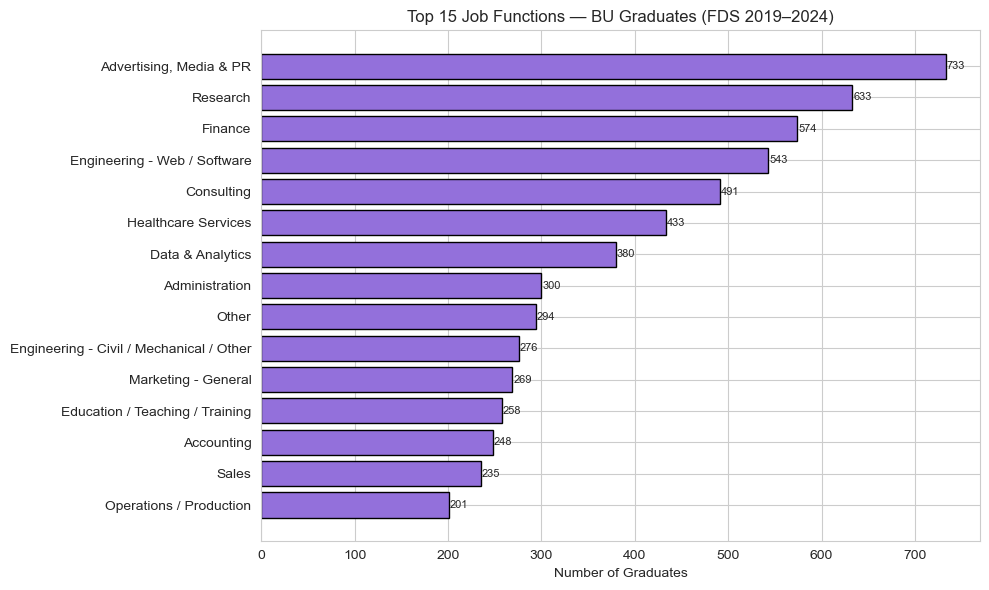

In [4]:
top_jf = fds['Job Function'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_jf.index[::-1], top_jf.values[::-1], color='mediumpurple', edgecolor='black')
for i, v in enumerate(top_jf.values[::-1]):
    ax.text(v + 1, i, str(v), va='center', fontsize=8)
ax.set_xlabel('Number of Graduates')
ax.set_title('Top 15 Job Functions — BU Graduates (FDS 2019–2024)')
plt.tight_layout()
plt.show()

## 1D. Outcomes by College and Major

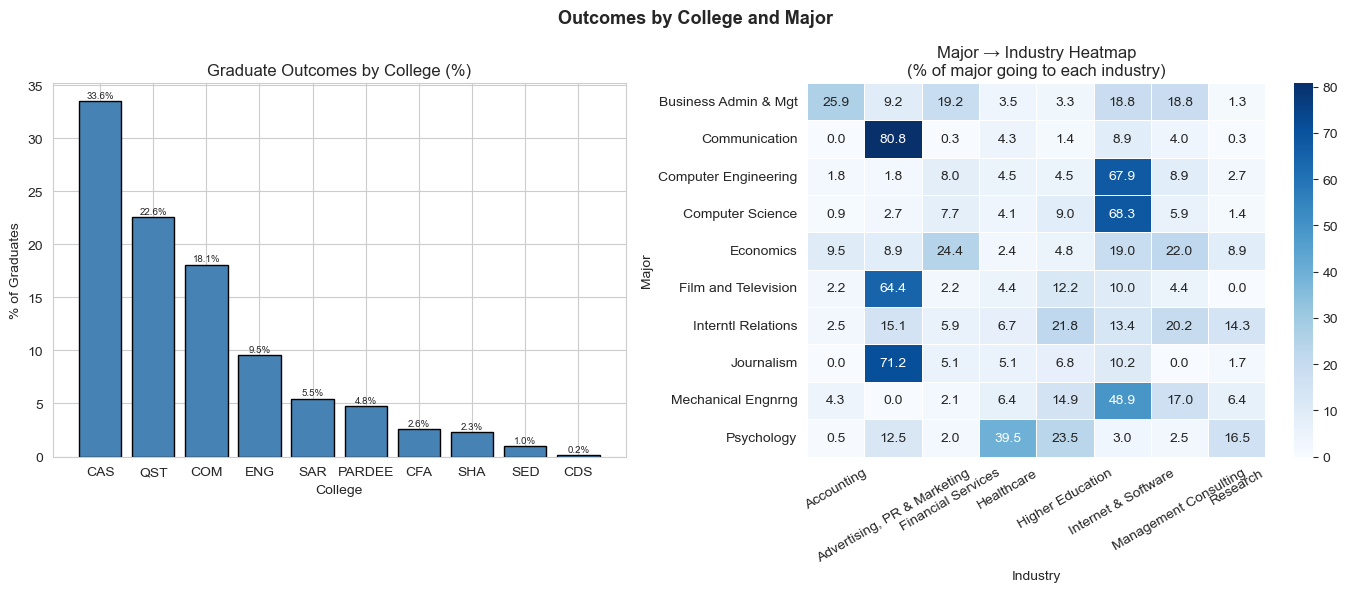

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# By college — as % per Jimmy feedback
college_counts = fds['Graduation Degree College_1'].value_counts()
college_pct = college_counts / college_counts.sum() * 100
bars = axes[0].bar(college_pct.index, college_pct.values, color='steelblue', edgecolor='black')
for bar, val in zip(bars, college_pct.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center', fontsize=7)
axes[0].set_xlabel('College')
axes[0].set_ylabel('% of Graduates')
axes[0].set_title('Graduate Outcomes by College (%)')

# Top major → top industry heatmap
top10_majors = fds['GRAD MAJOR #1'].value_counts().head(10).index
top8_industries = fds['Employer Industry'].value_counts().head(8).index
heatmap_data = fds[
    fds['GRAD MAJOR #1'].isin(top10_majors) &
    fds['Employer Industry'].isin(top8_industries)
].groupby(['GRAD MAJOR #1', 'Employer Industry']).size().unstack(fill_value=0)
# Normalize to % within each major row
heatmap_pct = heatmap_data.div(heatmap_data.sum(axis=1), axis=0) * 100

sns.heatmap(heatmap_pct, ax=axes[1], cmap='Blues', annot=True, fmt='.1f', linewidths=0.5)
axes[1].set_title('Major → Industry Heatmap\n(% of major going to each industry)')
axes[1].set_xlabel('Industry')
axes[1].set_ylabel('Major')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle('Outcomes by College and Major', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 1E. Demographics Breakdown
> Note: Gender has two coding schemes in the raw data (Man/Woman and Male/Female). Normalized to Man/Woman. Domestic/International '?' treated as Unknown.

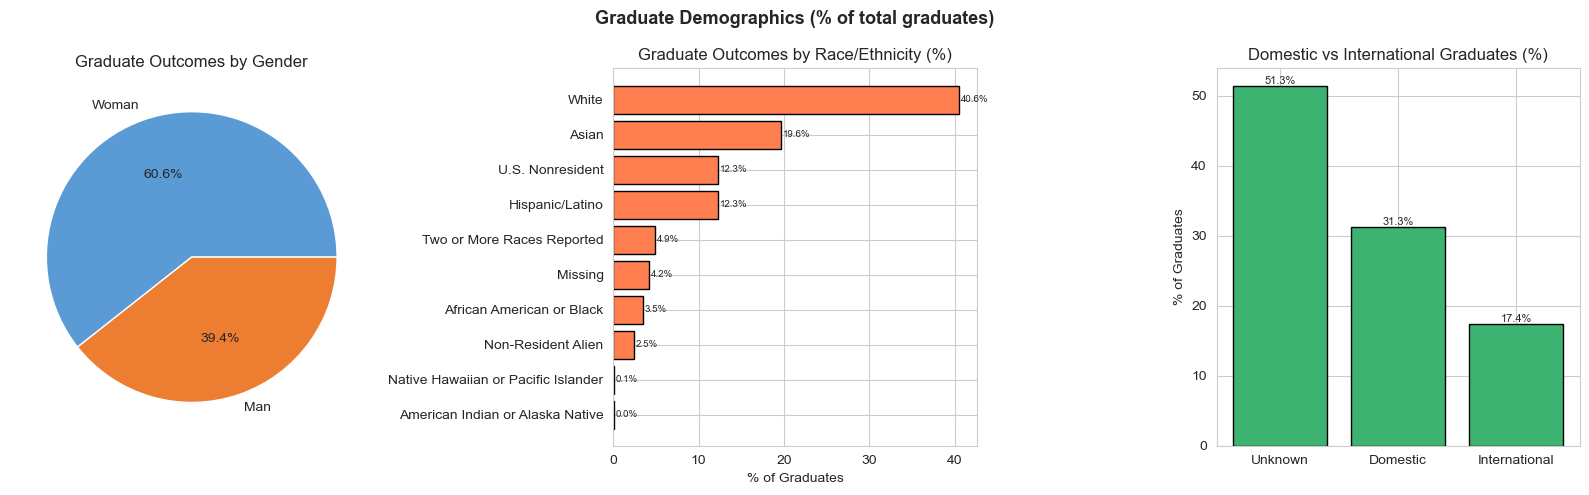

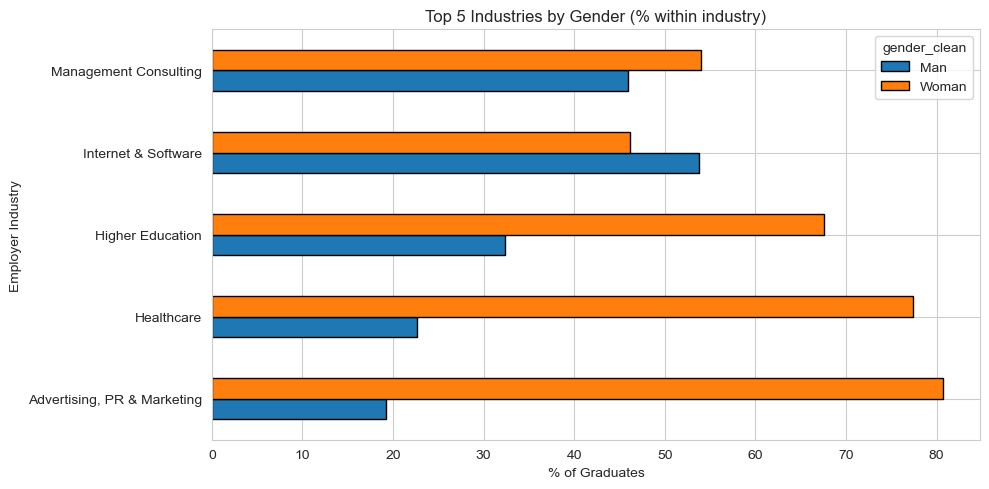

Note: BU has more women graduates overall — percentages reflect that baseline.
              count
gender_clean       
Woman          6065
Man            3939
Women share: 60.6%


In [6]:
# 1E. Demographics — expressed as percentages per Jimmy's feedback

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Gender — pie already shows %
gender_counts = fds['gender_clean'].value_counts()
axes[0].pie(gender_counts.values, labels=gender_counts.index,
            autopct='%1.1f%%', colors=['#5B9BD5','#ED7D31','#A9D18E'])
axes[0].set_title('Graduate Outcomes by Gender')

# Race/Ethnicity — convert to %
race = fds['Student IPEDS Race Ethnicity'].value_counts()
race_pct = race / race.sum() * 100
axes[1].barh(race_pct.index[::-1], race_pct.values[::-1], color='coral', edgecolor='black')
for i, v in enumerate(race_pct.values[::-1]):
    axes[1].text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=7)
axes[1].set_xlabel('% of Graduates')
axes[1].set_title('Graduate Outcomes by Race/Ethnicity (%)')

# Domestic vs International — convert to %
intl_counts = fds['intl_clean'].value_counts()
intl_pct = intl_counts / intl_counts.sum() * 100
bars = axes[2].bar(intl_pct.index, intl_pct.values, color='mediumseagreen', edgecolor='black')
for bar, val in zip(bars, intl_pct.values):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center', fontsize=8)
axes[2].set_ylabel('% of Graduates')
axes[2].set_title('Domestic vs International Graduates (%)')

plt.suptitle('Graduate Demographics (% of total graduates)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Industry by gender — as percentages
top5_ind = fds['Employer Industry'].value_counts().head(5).index
gender_ind = fds[fds['Employer Industry'].isin(top5_ind)]\
    .groupby(['Employer Industry','gender_clean']).size().unstack(fill_value=0)
gender_ind_pct = gender_ind.div(gender_ind.sum(axis=1), axis=0) * 100
gender_ind_pct.plot(kind='barh', figsize=(10, 5), edgecolor='black')
plt.title('Top 5 Industries by Gender (% within industry)')
plt.xlabel('% of Graduates')
plt.tight_layout()
plt.show()

# Note on BU gender composition
print('Note: BU has more women graduates overall — percentages reflect that baseline.')
print(gender_counts.rename('count').to_frame())
print(f"Women share: {100*gender_counts.get('Woman',0)/gender_counts.sum():.1f}%")

## 1F. Geographic Distribution

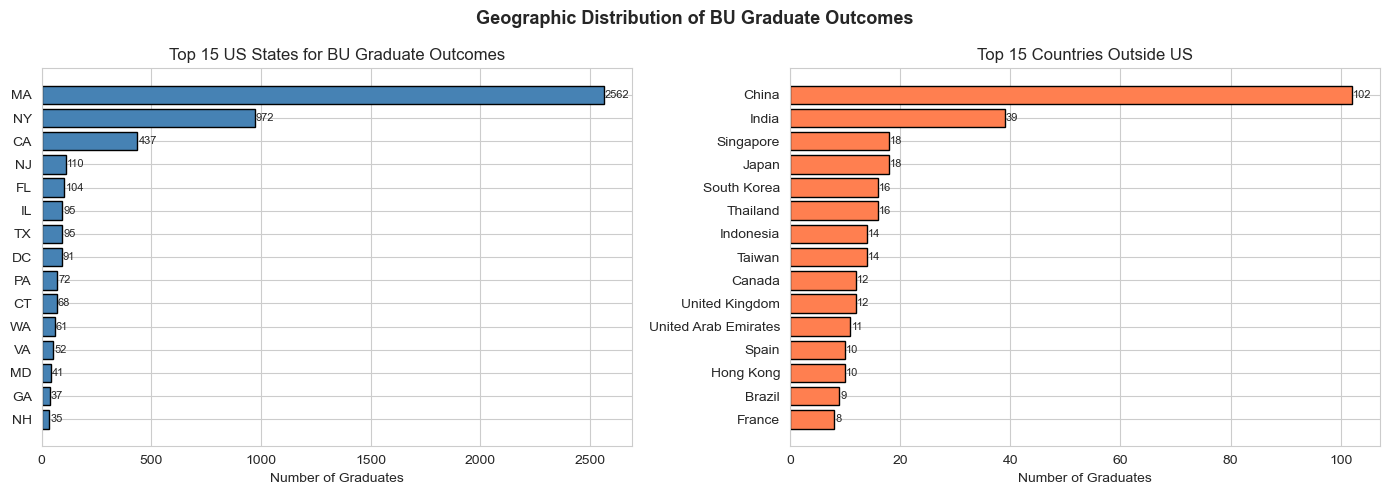

Graduates staying in US: 5,129 (92.5%)
Graduates going abroad: 417


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top US states
top_states = fds[fds['Outcome Country'] == 'United States of America']\
    ['Outcome State'].value_counts().head(15)
axes[0].barh(top_states.index[::-1], top_states.values[::-1], color='steelblue', edgecolor='black')
axes[0].set_xlabel('Number of Graduates')
axes[0].set_title('Top 15 US States for BU Graduate Outcomes')
for i, v in enumerate(top_states.values[::-1]):
    axes[0].text(v + 5, i, str(v), va='center', fontsize=8)

# Top countries (excluding US)
top_countries = fds[fds['Outcome Country'] != 'United States of America']\
    ['Outcome Country'].value_counts().head(15)
axes[1].barh(top_countries.index[::-1], top_countries.values[::-1], color='coral', edgecolor='black')
axes[1].set_xlabel('Number of Graduates')
axes[1].set_title('Top 15 Countries Outside US')
for i, v in enumerate(top_countries.values[::-1]):
    axes[1].text(v + 0.2, i, str(v), va='center', fontsize=8)

plt.suptitle('Geographic Distribution of BU Graduate Outcomes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

us_pct = (fds['Outcome Country'] == 'United States of America').sum()
print(f'Graduates staying in US: {us_pct:,} ({100*us_pct/fds["Outcome Country"].notna().sum():.1f}%)')
print(f'Graduates going abroad: {fds["Outcome Country"].notna().sum() - us_pct:,}')

## 1G. Year-over-Year Trends (2019 - 2024)

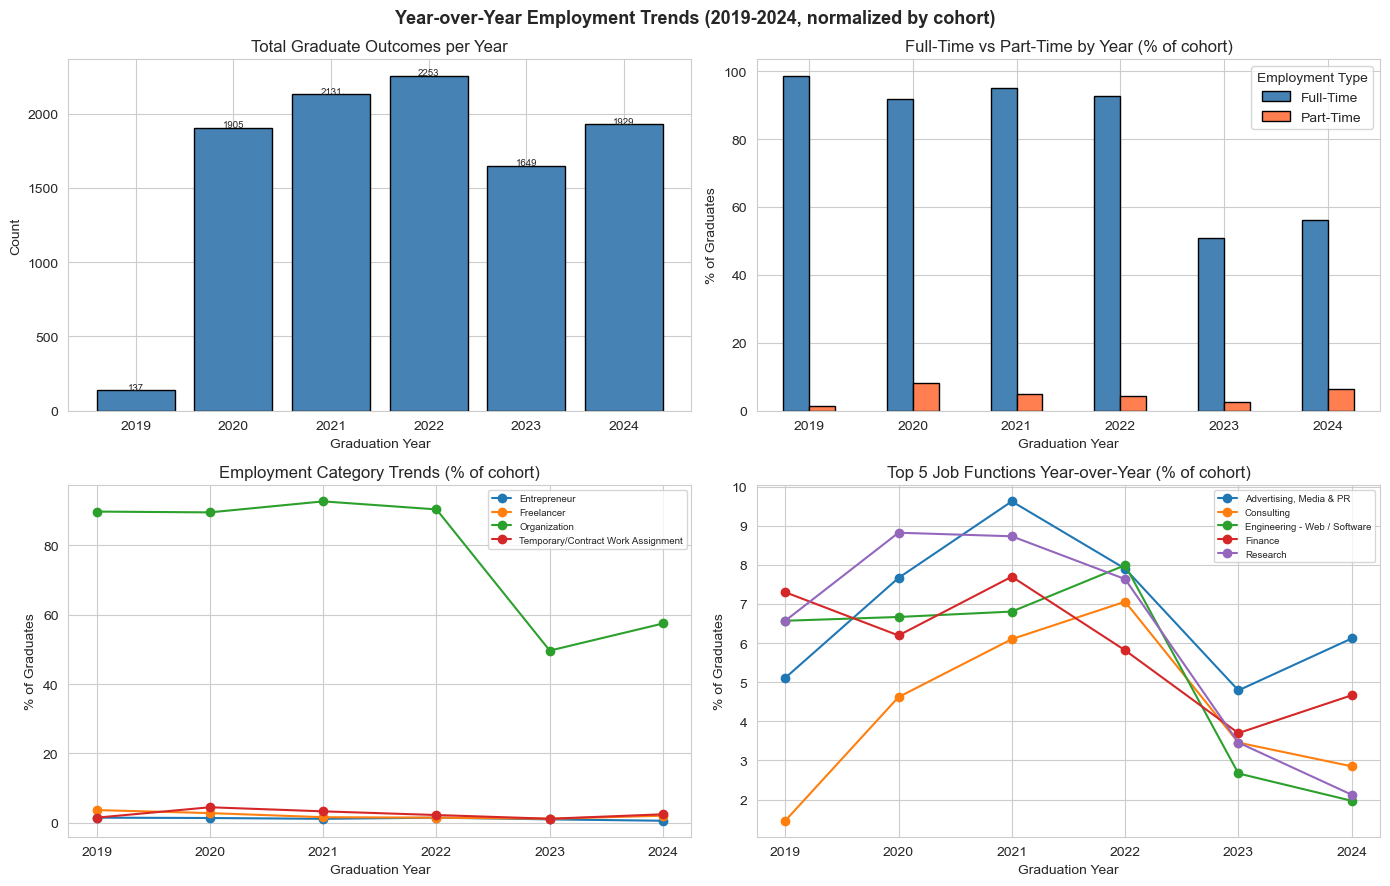

In [8]:
cohort_size_yr = fds.groupby('grad_year').size().rename('cohort_size')

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Total outcomes by year
by_year = fds.groupby('grad_year').size()
axes[0,0].bar(by_year.index, by_year.values, color='steelblue', edgecolor='black')
for i, (yr, v) in enumerate(by_year.items()):
    axes[0,0].text(yr, v + 5, str(v), ha='center', fontsize=7)
axes[0,0].set_title('Total Graduate Outcomes per Year')
axes[0,0].set_xlabel('Graduation Year')
axes[0,0].set_ylabel('Count')

# Full-time vs part-time by year — as % of cohort
emp_type_year = fds.groupby(['grad_year','Employment Type']).size().unstack(fill_value=0)
emp_type_pct = emp_type_year.div(cohort_size_yr, axis=0) * 100
emp_type_pct.plot(kind='bar', ax=axes[0,1], edgecolor='black', color=['steelblue','coral'])
axes[0,1].set_title('Full-Time vs Part-Time by Year (% of cohort)')
axes[0,1].set_xlabel('Graduation Year')
axes[0,1].set_ylabel('% of Graduates')
axes[0,1].tick_params(axis='x', rotation=0)

# Employment category by year — as % of cohort
top_cats = ['Organization', 'Temporary/Contract Work Assignment', 'Freelancer', 'Entrepreneur']
cat_year = fds[fds['Employment Category'].isin(top_cats)]\
    .groupby(['grad_year','Employment Category']).size().unstack(fill_value=0)
cat_year_pct = cat_year.div(cohort_size_yr, axis=0) * 100
cat_year_pct.plot(ax=axes[1,0], marker='o')
axes[1,0].set_title('Employment Category Trends (% of cohort)')
axes[1,0].set_xlabel('Graduation Year')
axes[1,0].set_ylabel('% of Graduates')
axes[1,0].legend(fontsize=7)

# Top job functions by year — as % of cohort
top5_jf = fds['Job Function'].value_counts().head(5).index
jf_year = fds[fds['Job Function'].isin(top5_jf)]\
    .groupby(['grad_year','Job Function']).size().unstack(fill_value=0)
jf_year_pct = jf_year.div(cohort_size_yr, axis=0) * 100
jf_year_pct.plot(ax=axes[1,1], marker='o')
axes[1,1].set_title('Top 5 Job Functions Year-over-Year (% of cohort)')
axes[1,1].set_xlabel('Graduation Year')
axes[1,1].set_ylabel('% of Graduates')
axes[1,1].legend(fontsize=7)

plt.suptitle('Year-over-Year Employment Trends (2019-2024, normalized by cohort)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
# Track 2: Handshake Bridge Analysis
Compares employers ranked highly by EEIS on Handshake against actual BU graduate placement in FDS.

**Contributor: Sviat Shevchenko**

**Method:** Manual name mapping of top 20 Handshake employers to FDS employer names. No programmatic join, FDS has no employer_id primary key and names are inconsistent across datasets.

**Key question:** Do employers that engage heavily on Handshake actually hire BU graduates at scale? Where the answer is no, those employers represent targeting opportunities for CCD.

## 2A. EEIS Rank vs FDS Hire Count - Bridge Table

In [9]:
# Load employer KPI table from Milestone 2 notebook output
employer_kpi = pd.read_csv(os.path.join(DATA_DIR, 'employer_kpi.csv'))

# Use EEIS_equal as primary score, compute percentile per Jimmy feedback
eeis_col = 'EEIS_equal' if 'EEIS_equal' in employer_kpi.columns else 'EEIS'
employer_kpi['eeis_pct'] = employer_kpi[eeis_col].rank(pct=True) * 100
employer_kpi['eeis_rank'] = employer_kpi[eeis_col].rank(ascending=False, method='min').astype(int)

# Take top 20 by EEIS rank
top20 = employer_kpi.nsmallest(20, 'eeis_rank')[['employer_name', eeis_col, 'eeis_pct', 'eeis_rank']].copy()

# FDS search string
top20['fds_search'] = (
    top20['employer_name']
    .str.lower()
    .str.replace(r'\s+(llp|inc|corp|ltd|co|llc|&|company)\.?$', '', regex=True)
    .str.strip()
)

# Manual overrides for known mismatches
overrides = {
    'jpmorganchase': 'jpmorgan',
    'pwc': 'pricewaterhous',
    'google, inc.': 'google',
    'kpmg llp': 'kpmg',
}
top20['fds_search'] = top20['employer_name'].apply(
    lambda x: overrides.get(x, top20.loc[top20['employer_name']==x, 'fds_search'].values[0])
)

fds_lower = fds['Employer Name'].str.lower().fillna('')
top20['fds_hires'] = top20['fds_search'].apply(
    lambda s: fds_lower.str.contains(s, na=False).sum()
)

top20['fds_hire_rank'] = top20['fds_hires'].rank(ascending=False, method='min').astype(int)
top20['rank_gap'] = top20['fds_hire_rank'] - top20['eeis_rank']
top20['flag'] = top20['rank_gap'].apply(
    lambda x: 'Targeting Opportunity' if x <= -5 else ('Strong Converter' if x >= 5 else 'Balanced')
)

bridge = top20.copy()

print('Bridge Table: EEIS Percentile vs FDS Hire Count')
display(bridge[['employer_name', 'eeis_pct', 'eeis_rank', 'fds_hires', 'fds_hire_rank', 'rank_gap', 'flag']]
        .sort_values('eeis_rank').round(1))

Bridge Table: EEIS Percentile vs FDS Hire Count


/var/folders/hv/tcqdmtjd09j4hgvm2929vjbh0000gn/T/ipykernel_9330/575545957.py:2: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  employer_kpi = pd.read_csv(os.path.join(DATA_DIR, 'employer_kpi.csv'))


,employer_name,eeis_pct,eeis_rank,fds_hires,fds_hire_rank,rank_gap,flag
0,ey,100.0,1,306,2,1,Balanced
1,jpmorganchase,100.0,2,43,9,7,Strong Converter
2,amazon,100.0,3,107,5,2,Balanced
3,pwc,100.0,4,163,3,-1,Balanced
4,morgan stanley,100.0,5,15,14,9,Strong Converter
5,mckinsey & company,100.0,6,12,15,9,Strong Converter
6,goldman sachs,100.0,7,32,10,3,Balanced
7,kpmg llp,100.0,8,53,6,-2,Balanced
8,capital one,100.0,9,23,13,4,Balanced
9,deloitte,100.0,10,112,4,-6,Targeting Opportunity


## 2B. Engagement vs Placement Comparison

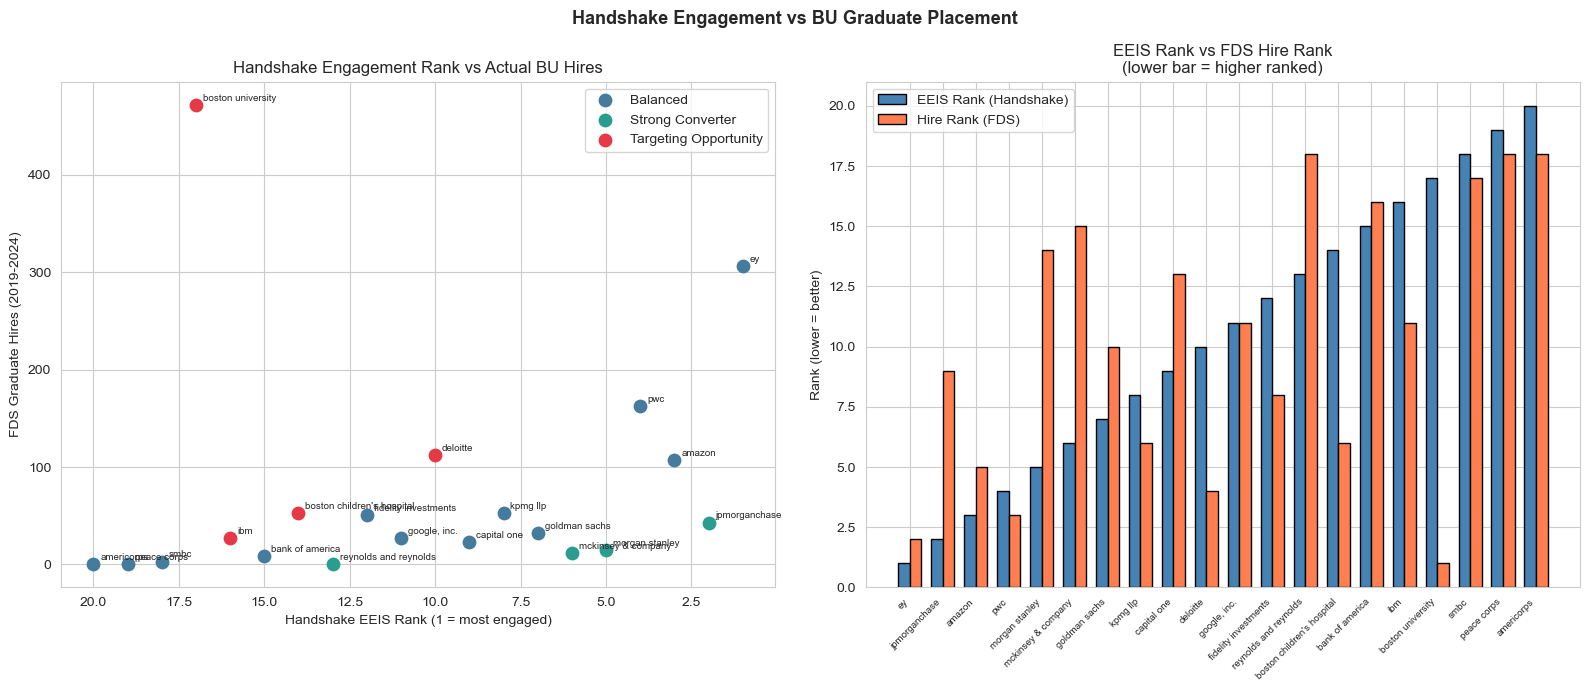

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: EEIS rank vs FDS hires scatter
colors = {'Targeting Opportunity': '#e63946', 'Strong Converter': '#2a9d8f', 'Balanced': '#457b9d'}
for flag, grp in bridge.groupby('flag'):
    axes[0].scatter(grp['eeis_rank'], grp['fds_hires'],
                    label=flag, color=colors[flag], s=80, zorder=3)
    for _, row in grp.iterrows():
        axes[0].annotate(row['employer_name'],
                         (row['eeis_rank'], row['fds_hires']),
                         textcoords='offset points', xytext=(5, 3), fontsize=7)

axes[0].set_xlabel('Handshake EEIS Rank (1 = most engaged)')
axes[0].set_ylabel('FDS Graduate Hires (2019-2024)')
axes[0].set_title('Handshake Engagement Rank vs Actual BU Hires')
axes[0].legend()
axes[0].invert_xaxis()

# Right: side-by-side rank comparison
bridge_sorted = bridge.sort_values('eeis_rank')
x = range(len(bridge_sorted))
width = 0.35

axes[1].bar([i - width/2 for i in x], bridge_sorted['eeis_rank'],
            width, label='EEIS Rank (Handshake)', color='steelblue', edgecolor='black')
axes[1].bar([i + width/2 for i in x], bridge_sorted['fds_hire_rank'],
            width, label='Hire Rank (FDS)', color='coral', edgecolor='black')
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(bridge_sorted['employer_name'], rotation=45, ha='right', fontsize=7)
axes[1].set_ylabel('Rank (lower = better)')
axes[1].set_title('EEIS Rank vs FDS Hire Rank\n(lower bar = higher ranked)')
axes[1].legend()

plt.suptitle('Handshake Engagement vs BU Graduate Placement', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 2C. CCD Targeting Opportunities
Employers flagged as **Targeting Opportunities** rank high on Handshake engagement (EEIS) but produce relatively few BU graduate hires. These are employers already investing in campus presence, CCD could work to convert that engagement into actual placement outcomes.

**Strong Converters** are employers where FDS hire rank significantly exceeds EEIS rank, they hire BU graduates at high rates relative to their Handshake engagement, suggesting off-platform or relationship-driven hiring that Handshake doesn't fully capture.

In [11]:
# Targeting opportunities — high engagement, low conversion
targeting = bridge[bridge['flag'] == 'Targeting Opportunity'].sort_values('eeis_rank')
converters = bridge[bridge['flag'] == 'Strong Converter'].sort_values('fds_hires', ascending=False)

print('=== TARGETING OPPORTUNITIES (High EEIS, Low FDS Hires) ===')
print('These employers are active on Handshake but under-convert to BU placements.')
display(targeting[['employer_name', 'eeis_rank', 'fds_hires', 'fds_hire_rank', 'rank_gap']])

print('\n=== STRONG CONVERTERS (High FDS Hires relative to EEIS Rank) ===')
print('These employers hire BU graduates at high rates beyond Handshake engagement alone.')
display(converters[['employer_name', 'eeis_rank', 'fds_hires', 'fds_hire_rank', 'rank_gap']])

# Breakdown: what functions/industries do hires go into at top converters
if len(converters) > 0:
    top_converter = converters.iloc[0]['fds_search']
    converter_hires = fds[fds['Employer Name'].str.lower().str.contains(top_converter, na=False)]
    print(f'\nJob functions for top converter ({converters.iloc[0]["employer_name"]}):')
    print(converter_hires['Job Function'].value_counts().head(8))

=== TARGETING OPPORTUNITIES (High EEIS, Low FDS Hires) ===
These employers are active on Handshake but under-convert to BU placements.


,employer_name,eeis_rank,fds_hires,fds_hire_rank,rank_gap
9,deloitte,10,112,4,-6
13,boston children's hospital,14,53,6,-8
15,ibm,16,27,11,-5
16,boston university,17,472,1,-16



=== STRONG CONVERTERS (High FDS Hires relative to EEIS Rank) ===
These employers hire BU graduates at high rates beyond Handshake engagement alone.


,employer_name,eeis_rank,fds_hires,fds_hire_rank,rank_gap
1,jpmorganchase,2,43,9,7
4,morgan stanley,5,15,14,9
5,mckinsey & company,6,12,15,9
12,reynolds and reynolds,13,0,18,5



Job functions for top converter (jpmorganchase):
Job Function
Finance                         21
Accounting                       4
Engineering - Web / Software     4
Data & Analytics                 3
Business Development             2
Product / Project Management     1
Name: count, dtype: int64


## 2D. FDS Profile for Top Handshake Employers
For each matched employer, shows what BU graduates actually do there; job function, major, college, and graduation year trend.

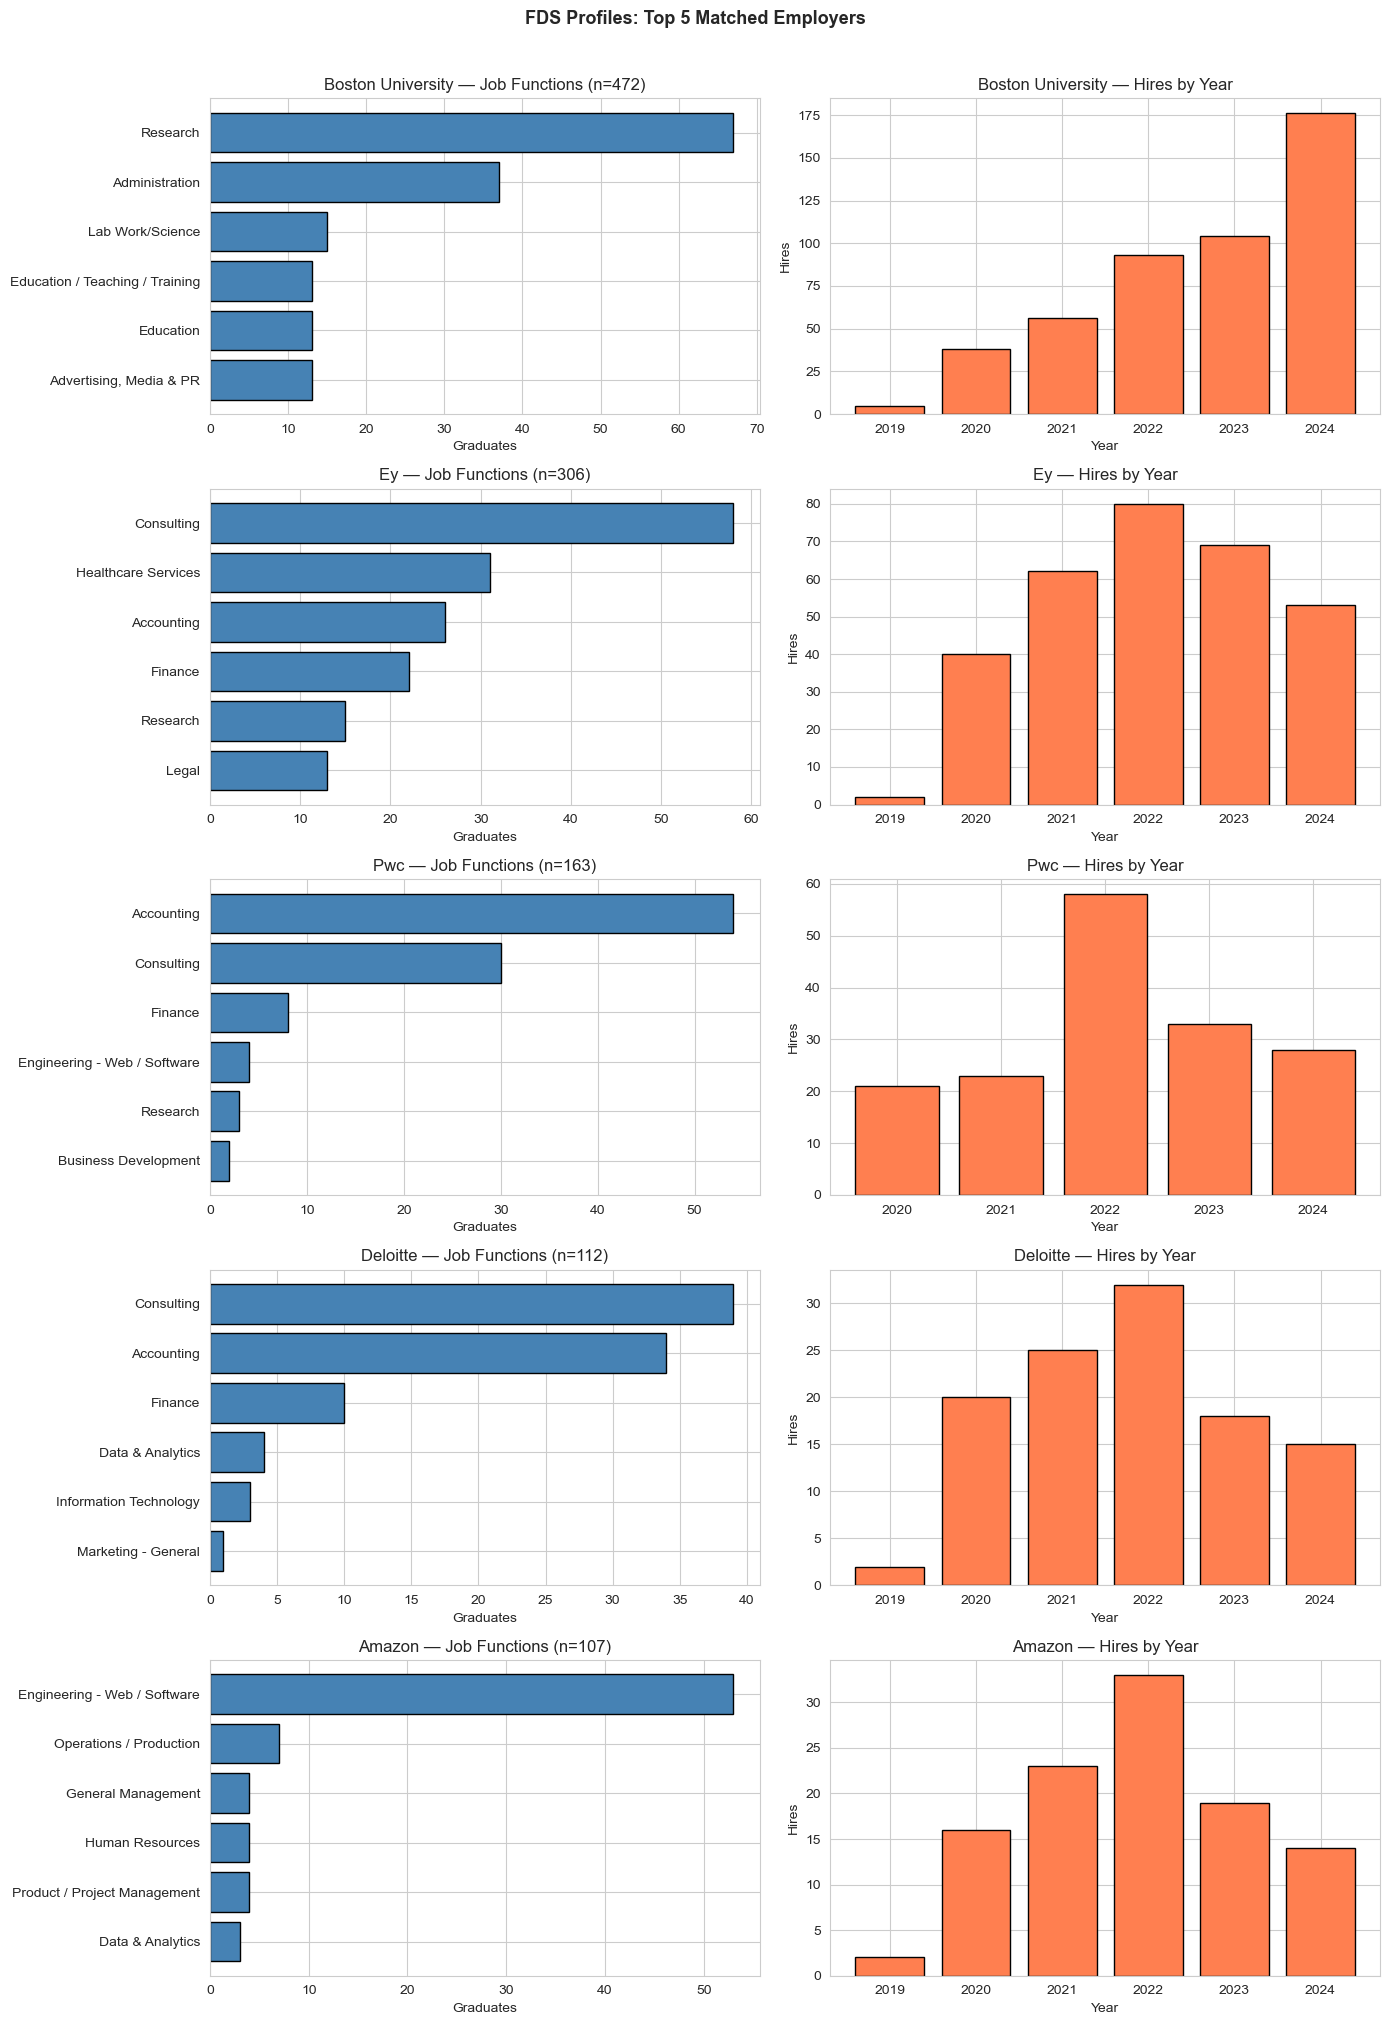

In [12]:
# Pick top 5 matched employers by FDS hires for detailed profile
top5_bridge = bridge.nlargest(5, 'fds_hires')

fig, axes = plt.subplots(len(top5_bridge), 2, figsize=(14, 4*len(top5_bridge)))

for idx, (_, row) in enumerate(top5_bridge.iterrows()):
    emp_fds = fds[fds['Employer Name'].str.lower().str.contains(row['fds_search'], na=False)]

    # Job function
    jf = emp_fds['Job Function'].value_counts().head(6)
    axes[idx, 0].barh(jf.index[::-1], jf.values[::-1], color='steelblue', edgecolor='black')
    axes[idx, 0].set_title(f"{row['employer_name'].title()} — Job Functions (n={len(emp_fds)})")
    axes[idx, 0].set_xlabel('Graduates')

    # Trend by year
    yr = emp_fds.groupby('grad_year').size()
    axes[idx, 1].bar(yr.index, yr.values, color='coral', edgecolor='black')
    axes[idx, 1].set_title(f"{row['employer_name'].title()} — Hires by Year")
    axes[idx, 1].set_xlabel('Year')
    axes[idx, 1].set_ylabel('Hires')

plt.suptitle('FDS Profiles: Top 5 Matched Employers', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
# Track 3: Student Outcome Analysis
**Contributor: Shaotai Hu**

Joins Handshake employer activity with FDS student outcomes to analyze relationships between employer engagement on Handshake and actual BU student hiring outcomes.

/var/folders/hv/tcqdmtjd09j4hgvm2929vjbh0000gn/T/ipykernel_9330/1213736818.py:17: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  ep_joined = pd.read_csv(os.path.join(DATA_DIR, 'ep_joined.csv'))


employer_metrics shape: (56089, 11)
Max num_outcomes: 408
Employers with outcomes: 1,073


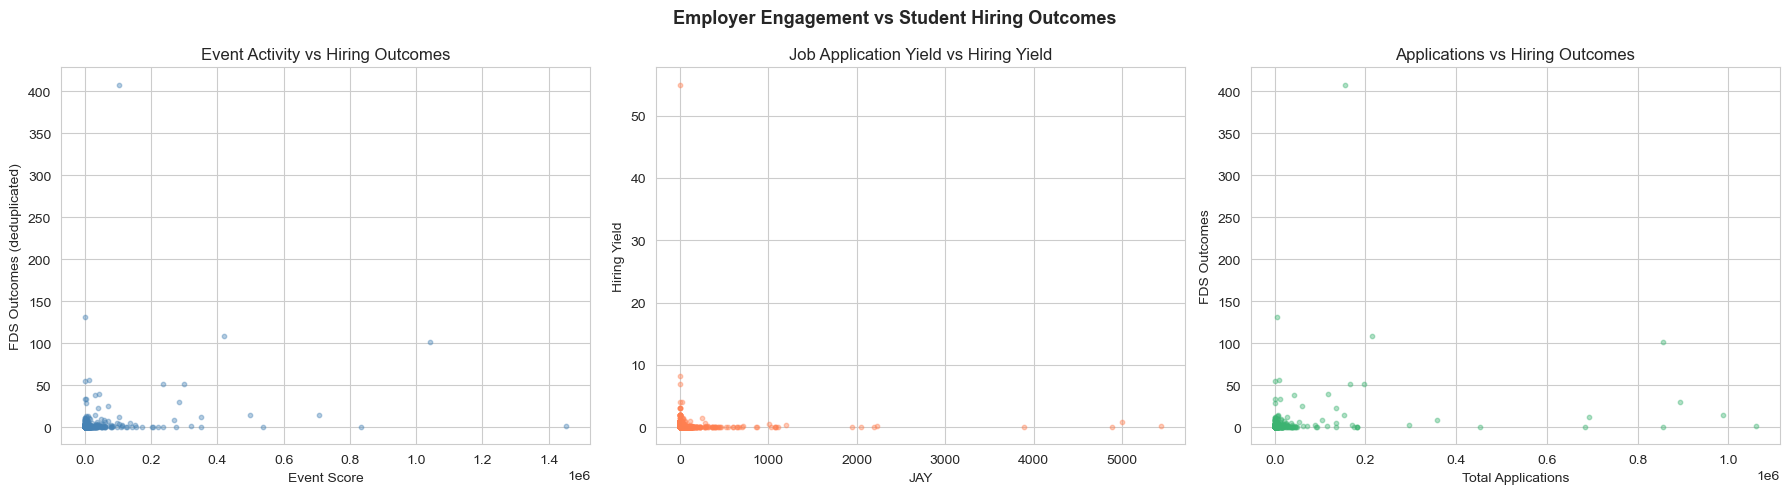

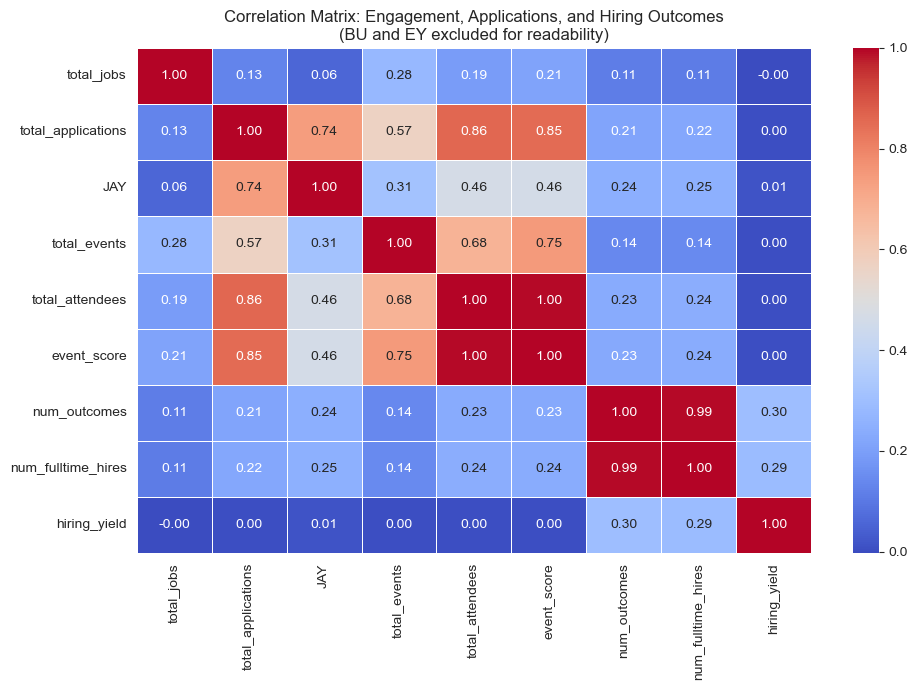

In [13]:
# Track 3: Student Outcome Analysis
# Contributor: Shaotai Hu (data loading, ep_outcomes, visualizations)
# Fix: employer_metrics rebuilt correctly (Sviat Shevchenko)
#   — outcome counts aggregated directly from outcomes.csv (one row per student)
#   — avoids inflation from employer x job x event join expansion

# 1. Imports & Setup
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

# 2. Load Data
DATA_DIR = ''
ep_joined = pd.read_csv(os.path.join(DATA_DIR, 'ep_joined.csv'))
outcomes  = pd.read_csv(os.path.join(DATA_DIR, 'outcomes.csv'))

# 3. Clean & Prepare Keys
ep_joined['employer_name_clean'] = (
    ep_joined['employer_name'].astype(str).str.strip().str.lower()
)
outcomes['Employer Name Clean'] = (
    outcomes['Employer Name'].astype(str).str.strip().str.lower()
)

# 4. Build ep_outcomes for Shaotai's heatmap and visualizations
#    Note: ep_outcomes is used for the correlation heatmap only.
#    Do NOT use ep_outcomes to aggregate outcome counts — see Step 6.
outcomes_employer = outcomes.groupby('Employer Name Clean').agg({
    'Outcome': 'count',
    'Employment Category': lambda x: (x == 'Organization').sum(),
    'Employment Type': lambda x: (x == 'Full-Time').sum()
}).rename(columns={
    'Outcome': 'num_outcomes',
    'Employment Category': 'num_org_hires',
    'Employment Type': 'num_fulltime_hires'
})

ep_outcomes = ep_joined.merge(
    outcomes_employer, how='left',
    left_on='employer_name_clean', right_on='Employer Name Clean'
)
ep_outcomes[['num_outcomes','num_org_hires','num_fulltime_hires']] = \
    ep_outcomes[['num_outcomes','num_org_hires','num_fulltime_hires']].fillna(0)
ep_outcomes.to_csv(os.path.join(DATA_DIR, 'ep_outcomes.csv'), index=False)

# 5. Build employer_metrics — Handshake activity from ep_joined
employer_metrics = ep_joined.groupby('employer_id').agg(
    total_jobs=('jobs_id', 'nunique'),
    total_applications=('applications_count', 'sum'),
    total_events=('events_name', lambda x: x.notna().sum()),
    total_attendees=('student_attendees_count', 'sum')
).reset_index()

employer_metrics['JAY'] = (
    employer_metrics['total_applications'] /
    employer_metrics['total_jobs'].replace(0, np.nan)
)
employer_metrics['event_score'] = (
    employer_metrics['total_events'] + employer_metrics['total_attendees']
)

# 6. Correct outcome counts — aggregate from outcomes.csv directly
#    (NOT from ep_outcomes which inflates counts via the join)
outcomes_clean = outcomes.copy()
outcomes_clean['employer_name_clean'] = (
    outcomes_clean['Employer Name'].str.lower().str.strip()
)
fds_counts = outcomes_clean.groupby('employer_name_clean').agg(
    num_outcomes=('Outcome', 'count'),
    num_fulltime_hires=('Employment Type', lambda x: (x == 'Full-Time').sum())
).reset_index()

# Bridge FDS names to Handshake employer_id via name match
name_bridge = ep_joined[['employer_id', 'employer_name']]\
    .drop_duplicates(subset=['employer_id']).copy()
name_bridge['employer_name_clean'] = (
    name_bridge['employer_name'].str.lower().str.strip()
)
fds_counts = fds_counts.merge(
    name_bridge[['employer_id', 'employer_name_clean']],
    on='employer_name_clean', how='left'
).drop_duplicates(subset=['employer_name_clean'], keep='first')

# Merge correct outcome counts into employer_metrics
employer_metrics = employer_metrics.merge(
    fds_counts[['employer_id', 'num_outcomes', 'num_fulltime_hires']],
    on='employer_id', how='left'
)
employer_metrics[['num_outcomes', 'num_fulltime_hires']] = \
    employer_metrics[['num_outcomes', 'num_fulltime_hires']].fillna(0)
employer_metrics['hiring_yield'] = (
    employer_metrics['num_outcomes'] /
    employer_metrics['total_jobs'].replace(0, np.nan)
)

# Add employer_name
name_map = ep_joined.drop_duplicates(subset=['employer_id'])[
    ['employer_id', 'employer_name']
]
employer_metrics = employer_metrics.merge(name_map, on='employer_id', how='left')

print(f'employer_metrics shape: {employer_metrics.shape}')
print(f'Max num_outcomes: {employer_metrics["num_outcomes"].max():.0f}')
print(f'Employers with outcomes: {(employer_metrics["num_outcomes"] > 0).sum():,}')

# 7. Visualizations (Shaotai's original — use ep_outcomes for heatmap)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Event Score vs Hiring Outcomes
axes[0].scatter(employer_metrics['event_score'],
                employer_metrics['num_outcomes'], alpha=0.4, s=10, color='steelblue')
axes[0].set_xlabel('Event Score')
axes[0].set_ylabel('FDS Outcomes (deduplicated)')
axes[0].set_title('Event Activity vs Hiring Outcomes')

# JAY vs Hiring Yield
axes[1].scatter(employer_metrics['JAY'],
                employer_metrics['hiring_yield'], alpha=0.4, s=10, color='coral')
axes[1].set_xlabel('JAY')
axes[1].set_ylabel('Hiring Yield')
axes[1].set_title('Job Application Yield vs Hiring Yield')

# Applications vs Outcomes
axes[2].scatter(employer_metrics['total_applications'],
                employer_metrics['num_outcomes'], alpha=0.4, s=10, color='mediumseagreen')
axes[2].set_xlabel('Total Applications')
axes[2].set_ylabel('FDS Outcomes')
axes[2].set_title('Applications vs Hiring Outcomes')

plt.suptitle('Employer Engagement vs Student Hiring Outcomes',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Correlation Heatmap — BU and EY excluded per Jimmy feedback
exclude_heatmap = ['boston university', 'ey']
heatmap_data = employer_metrics[
    employer_metrics['employer_name'].notna() &
    (~employer_metrics['employer_name'].str.lower().isin(exclude_heatmap))
]
corr_cols = [
    'total_jobs', 'total_applications', 'JAY',
    'total_events', 'total_attendees', 'event_score',
    'num_outcomes', 'num_fulltime_hires', 'hiring_yield'
]
plt.figure(figsize=(10, 7))
sns.heatmap(
    heatmap_data[corr_cols].corr(),
    annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)
plt.title('Correlation Matrix: Engagement, Applications, and Hiring Outcomes\n'
          '(BU and EY excluded for readability)')
plt.tight_layout()
plt.show()

## Track 3 Extension: Client's Feedback Fixes
**Contributor: Sviat Shevchenko**

Addresses feedback from Client Meeting 4:
- Exclude BU and EY from correlation heatmap for readability
- Year-over-year hiring normalized by cohort
- EEIS displayed as percentiles

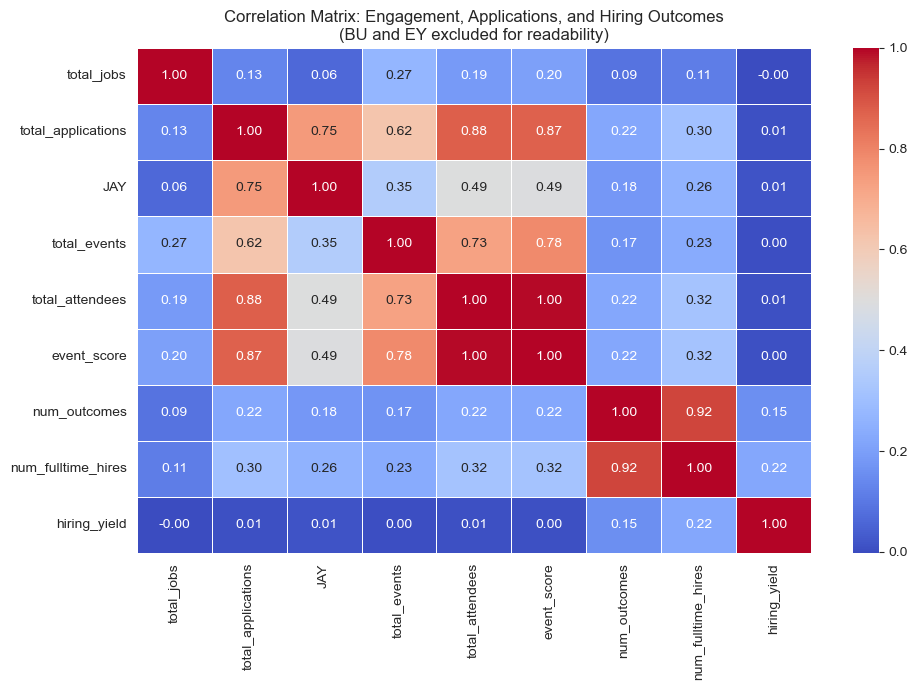

Employers in heatmap: 56,087 (excluded: BU, EY)


In [14]:
# Correlation Heatmap — BU and EY excluded per Jimmy's feedback
# Their dominance compresses the scale and makes other employers unreadable

employer_metrics['employer_name'] = ep_outcomes.groupby('employer_id')['employer_name'].first()

exclude_heatmap = ['boston university', 'ey']
heatmap_data = employer_metrics[
    ~employer_metrics['employer_name'].str.lower().fillna('').isin(exclude_heatmap)
]

corr_cols = [
    'total_jobs', 'total_applications', 'JAY',
    'total_events', 'total_attendees', 'event_score',
    'num_outcomes', 'num_fulltime_hires', 'hiring_yield'
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    heatmap_data[corr_cols].corr(),
    annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)
plt.title('Correlation Matrix: Engagement, Applications, and Hiring Outcomes\n'
          '(BU and EY excluded for readability)')
plt.tight_layout()
plt.show()

print(f"Employers in heatmap: {len(heatmap_data):,} (excluded: BU, EY)")

## Year-over-Year Hiring Normalized by Cohort
Addresses Jimmy's feedback: normalize employer hiring data year-over-year, express as % of graduating cohort rather than raw counts. Also check cohort merge handling.

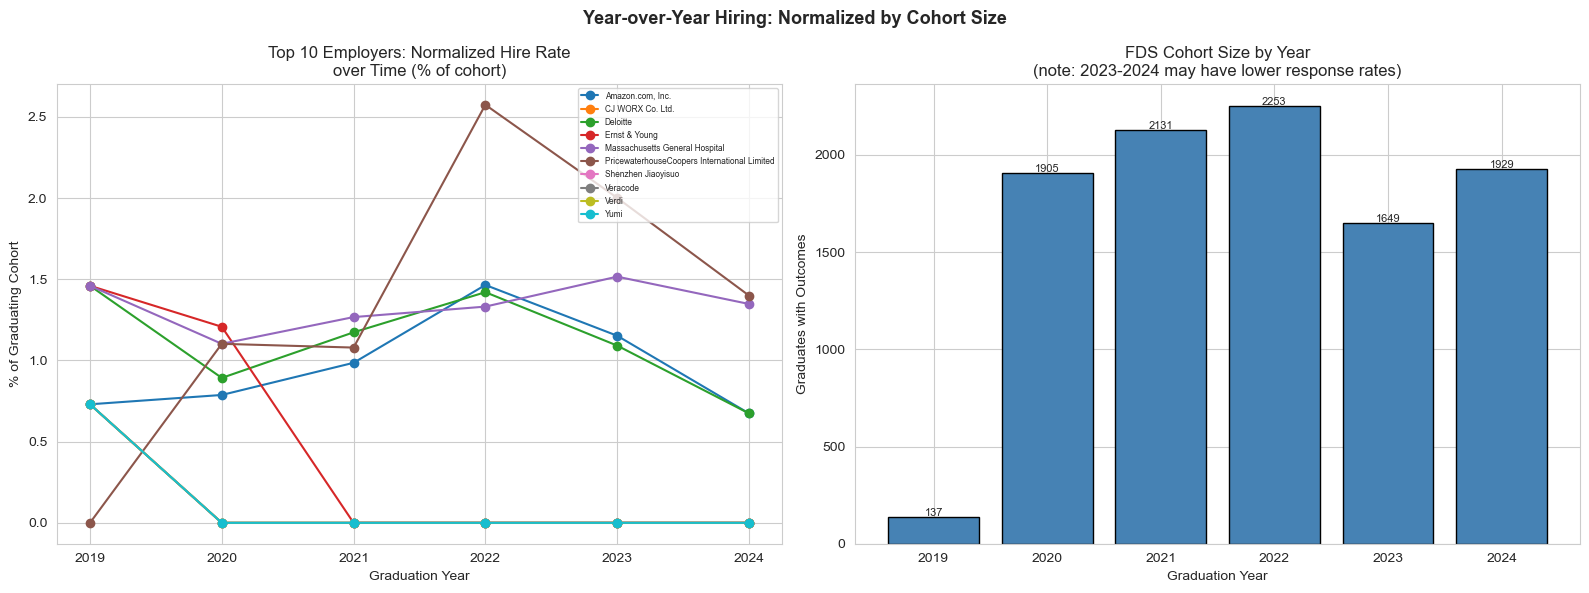

Note: Lower cohort sizes in 2023-2024 may reflect lower FDS data availability rates,
not actual declines in employment. Interpret year-over-year trends accordingly.


In [15]:
# YoY hiring normalized by cohort size
# Focus on top 10 employers (excl. BU and EY) as the client suggested

exclude_yoy = ['boston university', 'unknown', 'self-employed', 'ey']

cohort_size = fds.groupby('grad_year').size().reset_index(name='cohort_size')

hires_yoy = fds[
    ~fds['Employer Name'].str.lower().fillna('').isin(exclude_yoy)
].groupby(['grad_year', 'Employer Name']).size().reset_index(name='raw_hires')

hires_yoy = hires_yoy.merge(cohort_size, on='grad_year')
hires_yoy['hire_pct'] = hires_yoy['raw_hires'] / hires_yoy['cohort_size'] * 100

# Top 10 employers by avg normalized hire rate
top10_norm = hires_yoy.groupby('Employer Name')['hire_pct']\
    .mean().sort_values(ascending=False).head(10).index

yoy_pivot = hires_yoy[hires_yoy['Employer Name'].isin(top10_norm)]\
    .pivot_table(index='grad_year', columns='Employer Name',
                 values='hire_pct', fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Line chart: normalized hire rate over time
yoy_pivot.plot(ax=axes[0], marker='o')
axes[0].set_xlabel('Graduation Year')
axes[0].set_ylabel('% of Graduating Cohort')
axes[0].set_title('Top 10 Employers: Normalized Hire Rate\nover Time (% of cohort)')
axes[0].legend(fontsize=6, loc='upper right')

# Cohort size by year — shows normalization context
axes[1].bar(cohort_size['grad_year'], cohort_size['cohort_size'],
            color='steelblue', edgecolor='black')
for i, row in cohort_size.iterrows():
    axes[1].text(row['grad_year'], row['cohort_size'] + 5,
                 str(int(row['cohort_size'])), ha='center', fontsize=8)
axes[1].set_xlabel('Graduation Year')
axes[1].set_ylabel('Graduates with Outcomes')
axes[1].set_title('FDS Cohort Size by Year\n(note: 2023-2024 may have lower response rates)')

plt.suptitle('Year-over-Year Hiring: Normalized by Cohort Size',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Note: Lower cohort sizes in 2023-2024 may reflect lower FDS data availability rates,')
print('not actual declines in employment. Interpret year-over-year trends accordingly.')

## EEIS as Percentile Rankings
Addresses Jimmy's feedback: use percentile rankings instead of numerical rankings for all EEIS KPI displays. Both percentile and rank shown for reference.

Active employers (with jobs or events): 31,978
Top 15 Employers: EEIS Score, Percentile, and Rank (among active employers)


/var/folders/hv/tcqdmtjd09j4hgvm2929vjbh0000gn/T/ipykernel_9330/2992599115.py:5: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  employer_kpi = pd.read_csv(os.path.join(DATA_DIR, 'employer_kpi.csv'))


,employer_name,employer_type,EEIS_equal,EEIS_equal_pct,EEIS_equal_rank_pos,EEIS_pca,EEIS_pca_pct,EEIS_rank,EEIS_rank_pct
0,ey,accounting,0.56,100.00,1,0.65,100.00,99.90,99.97
1,jpmorganchase,financial services,0.44,100.00,2,0.49,99.99,99.97,100.00
2,amazon,internet & software,0.43,99.99,3,0.49,99.99,99.95,100.00
3,pwc,accounting,0.43,99.99,4,0.50,100.00,99.80,99.92
4,morgan stanley,investment banking,0.41,99.99,5,0.46,99.98,99.92,99.99
5,mckinsey & company,management consulting,0.40,99.98,6,0.46,99.99,99.75,99.88
6,goldman sachs,investment banking,0.40,99.98,7,0.46,99.98,99.72,99.85
7,kpmg llp,accounting,0.37,99.98,8,0.43,99.98,99.66,99.81
8,capital one,commercial banking & credit,0.33,99.97,9,0.38,99.97,98.29,97.85
9,deloitte,management consulting,0.32,99.97,10,0.37,99.97,99.78,99.91


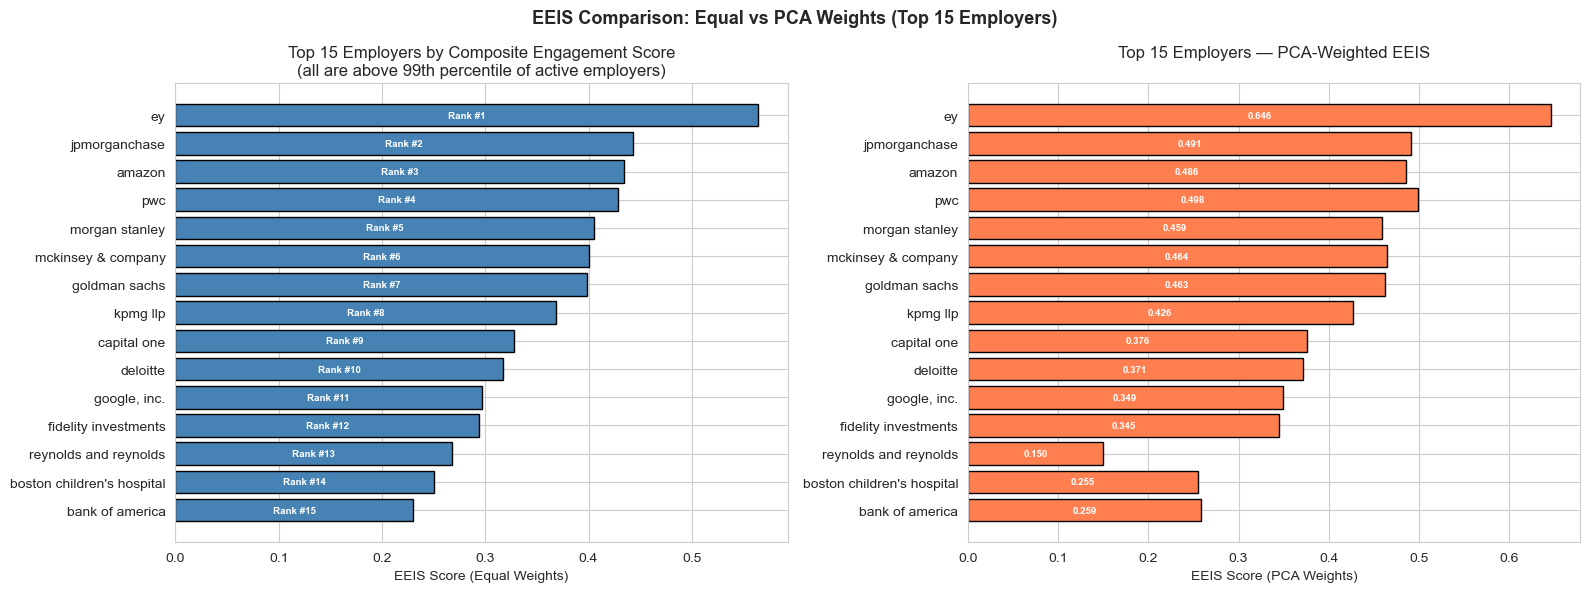

In [16]:
# EEIS displayed as percentiles for dashboard KPIs
# Fix: compute percentile among ACTIVE employers only (those with any jobs or events)
# All top 15 are in 99.9th+ pct when computed across all 56k employers so bar is meaningless

employer_kpi = pd.read_csv(os.path.join(DATA_DIR, 'employer_kpi.csv'))

# Filter to active employers only
active_kpi = employer_kpi[
    (employer_kpi['total_jobs'].fillna(0) > 0) |
    (employer_kpi['total_events_dedup'].fillna(0) > 0)
].copy()

print(f'Active employers (with jobs or events): {len(active_kpi):,}')

# Compute percentiles within active employers
for col in ['EEIS_equal', 'EEIS_pca', 'EEIS_rank']:
    if col in active_kpi.columns:
        active_kpi[f'{col}_pct'] = active_kpi[col].rank(pct=True) * 100
        active_kpi[f'{col}_rank_pos'] = active_kpi[col].rank(ascending=False, method='min').astype(int)

pct_cols = [c for c in ['employer_name', 'employer_type',
                          'EEIS_equal', 'EEIS_equal_pct', 'EEIS_equal_rank_pos',
                          'EEIS_pca', 'EEIS_pca_pct',
                          'EEIS_rank', 'EEIS_rank_pct'] if c in active_kpi.columns]

top15_pct = active_kpi.sort_values('EEIS_equal', ascending=False).head(15)[pct_cols]
print('Top 15 Employers: EEIS Score, Percentile, and Rank (among active employers)')
display(top15_pct.round(2))

# Bar chart — show EEIS score with rank label inside
# (percentile useless for top employers since all ~100th)
top15_vis = active_kpi.sort_values('EEIS_equal', ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: EEIS score with rank label
bars = axes[0].barh(top15_vis['employer_name'][::-1],
                    top15_vis['EEIS_equal'][::-1],
                    color='steelblue', edgecolor='black')
for bar, (_, row) in zip(bars, top15_vis[::-1].iterrows()):
    rank = int(row['EEIS_equal_rank_pos'])
    axes[0].text(bar.get_width()/2, bar.get_y() + bar.get_height()/2,
                 f'Rank #{rank}', ha='center', va='center',
                 fontsize=7, color='white', fontweight='bold')
axes[0].set_xlabel('EEIS Score (Equal Weights)')
axes[0].set_title('Top 15 Employers by Composite Engagement Score\n'
                  '(all are above 99th percentile of active employers)')

# Right: EEIS_pca score for comparison
if 'EEIS_pca' in top15_vis.columns:
    bars2 = axes[1].barh(top15_vis['employer_name'][::-1],
                         top15_vis['EEIS_pca'][::-1],
                         color='coral', edgecolor='black')
    for bar, (_, row) in zip(bars2, top15_vis[::-1].iterrows()):
        axes[1].text(bar.get_width()/2, bar.get_y() + bar.get_height()/2,
                     f"{row['EEIS_pca']:.3f}", ha='center', va='center',
                     fontsize=7, color='white', fontweight='bold')
    axes[1].set_xlabel('EEIS Score (PCA Weights)')
    axes[1].set_title('Top 15 Employers — PCA-Weighted EEIS\n')

plt.suptitle('EEIS Comparison: Equal vs PCA Weights (Top 15 Employers)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [17]:
# Cohort assignment validation - added per client's feedback (Meeting 4)
fds['year_from_semester'] = fds['Graduation Year Semester'].str.extract(r'(\d{4})').astype(float).astype('Int64')
mismatches = fds[fds['grad_year'] != fds['year_from_semester']]

print(f"Cohort Assignment Validation")
print(f"{'='*50}")
print(f"Students where semester label differs from degree conferral year: {len(mismatches):,} ({100*len(mismatches)/len(fds):.1f}%)")
print(f"All are Fall semester students conferred in January of the following year.")
print(f"grad_year correctly derived from 'Graduation Date' — no fix needed.\n")
print("Cohort sizes used in analysis:")
print(fds.groupby('grad_year').size().rename('cohort_size').to_string())

fds = fds.drop(columns=['year_from_semester'])

Cohort Assignment Validation
Students where semester label differs from degree conferral year: 1,177 (11.8%)
All are Fall semester students conferred in January of the following year.
grad_year correctly derived from 'Graduation Date' — no fix needed.

Cohort sizes used in analysis:
grad_year
2019     137
2020    1905
2021    2131
2022    2253
2023    1649
2024    1929


## Cohort Assignment Validation

**grad_year is derived from `Graduation Date`, not `Graduation Year Semester`.**

11.8% of graduates (n=1,177) have a semester label that differs from their actual degree conferral year — all are Fall semester students whose degrees were conferred in January of the following year.

| Case | Example | Correct Class |
|---|---|---|
| Fall semester → January conferral | Fall 2019 → Jan 2020 | 2020 ✅ |
| Summer semester → September conferral | Summer 2019 → Sep 2019 | 2019 ✅ |

Both cases are handled correctly because `grad_year` is extracted from `Graduation Date`. No reclassification needed.

> Note: Cohort size variation across years reflects both actual enrollment differences and lower FDS response rates in 2023–2024 (flagged by Jimmy, Meeting 4). Normalized hire rates use these cohort sizes as the denominator.

In [18]:
# Summary stats referenced in cohort validation
print('grad_year distribution (from Graduation Date — correct anchor):')
print(fds.groupby('grad_year').size().rename('cohort_size').to_string())
print()
print('Sep graduates (Summer session) → correctly in same calendar year (e.g. Sep 2019 → 2019)')
print('Jan graduates (Fall session)   → correctly in following calendar year (e.g. Jan 2020 → 2020)')
print('Both cases handled correctly by deriving grad_year from Graduation Date.')

grad_year distribution (from Graduation Date — correct anchor):
grad_year
2019     137
2020    1905
2021    2131
2022    2253
2023    1649
2024    1929

Sep graduates (Summer session) → correctly in same calendar year (e.g. Sep 2019 → 2019)
Jan graduates (Fall session)   → correctly in following calendar year (e.g. Jan 2020 → 2020)
Both cases handled correctly by deriving grad_year from Graduation Date.


# Power BI

In [27]:
# Export Power BI data tables

# ── Table 1: employer_kpi.csv — already exists, no changes needed ─────
print("Table 1: employer_kpi.csv — already exported from ms2")

# ── Table 2: fds_outcomes.csv ─────────────────────────────────────────
fds_export = fds[[
    # Graduate identifiers
    'grad_year',
    'Graduation Semester',
    'Graduation Degree College_1',
    'Graduation Degree College_2',
    'GRAD MAJOR #1',
    'GRAD MAJOR #2',
    # Demographics
    'gender_clean',
    'Student IPEDS Race Ethnicity',
    'intl_clean',
    # Outcome classification
    'Outcome',
    'Employment Category',
    'Employment Type',
    # Employer
    'Employer Name',
    'Employer Industry',
    # Role
    'Job Function',
    'Job Position',
    # Geography
    'Outcome City',
    'Outcome State',
    'Outcome Country',
]].copy().rename(columns={
    'gender_clean': 'gender',
    'intl_clean':   'domestic_international',
})

fds_export.to_csv(os.path.join(DATA_DIR, 'fds_outcomes.csv'), index=False)
print(f"\nTable 2: fds_outcomes.csv")
print(f"  Rows:    {len(fds_export):,}")
print(f"  Columns: {len(fds_export.columns)}")
print(f"  Columns: {fds_export.columns.tolist()}")

# ── Table 3: employer_name_bridge.csv ────────────────────────────────
# Start with top 200 EEIS employers — these are the ones that matter
# for the dashboard. Fuzzy match against FDS names, export for Tessa
# to review and correct in Excel before loading into Power BI.
from rapidfuzz import process, fuzz

top_kpi = employer_kpi.nlargest(200, 'EEIS_equal')[['employer_id', 'employer_name']].copy()
top_kpi['name_lower'] = top_kpi['employer_name'].str.lower().str.strip()

fds_emp_names = set(fds['Employer Name'].dropna().str.lower().str.strip().unique())
fds_names_original = {n.lower().strip(): n for n in fds['Employer Name'].dropna().str.strip().unique()}

results = []
for _, row in top_kpi.iterrows():
    name = row['name_lower']
    if name in fds_emp_names:
        fds_match = fds_names_original[name]
        status = 'exact'
        score = 100
    else:
        match, score, _ = process.extractOne(
            name, list(fds_emp_names), scorer=fuzz.token_sort_ratio
        )
        if score >= 80:
            fds_match = fds_names_original.get(match, match)
            status = 'fuzzy'
        else:
            fds_match = None
            status = 'no_match'

    results.append({
        'handshake_employer_name': row['employer_name'],
        'fds_employer_name':       fds_match,
        'match_type':              status,
        'match_score':             score
    })

bridge_df = pd.DataFrame(results)\
    .sort_values(['match_type', 'match_score'], ascending=[True, True])

bridge_df.to_csv(os.path.join(DATA_DIR, 'employer_name_bridge.csv'), index=False)

n_exact    = (bridge_df['match_type'] == 'exact').sum()
n_fuzzy    = (bridge_df['match_type'] == 'fuzzy').sum()
n_no_match = (bridge_df['match_type'] == 'no_match').sum()

print(f"\nTable 3: employer_name_bridge.csv")
print(f"  Total rows:   {len(bridge_df):,} (top 200 EEIS employers)")
print(f"  Exact match:  {n_exact:,}")
print(f"  Fuzzy match:  {n_fuzzy:,}  ← review these")
print(f"  No match:     {n_no_match:,} ← fill in manually")

print(f"\nFuzzy matches to review (sorted by score ascending = least confident first):")
display(bridge_df[bridge_df['match_type'] == 'fuzzy']\
    [['handshake_employer_name', 'fds_employer_name', 'match_score']]\
    .reset_index(drop=True))

print(f"\nNo matches — fill in fds_employer_name manually in Excel:")
display(bridge_df[bridge_df['match_type'] == 'no_match']\
    [['handshake_employer_name', 'fds_employer_name', 'match_score']]\
    .reset_index(drop=True))

print(f"\n── Summary ──────────────────────────────────────────────────")
print(f"  employer_kpi.csv     — {len(employer_kpi):,} rows, Handshake engagement KPIs")
print(f"  fds_outcomes.csv     — {len(fds_export):,} rows, graduate outcome records")
print(f"  employer_name_bridge.csv — {len(bridge_df):,} rows, name crosswalk for Power BI")
print(f"\nNext step: open employer_name_bridge.csv in Excel,")
print(f"  correct fuzzy matches and fill no_match rows,")
print(f"  then load all three files into Power BI.")

Table 1: employer_kpi.csv — already exported from ms2

Table 2: fds_outcomes.csv
  Rows:    10,004
  Columns: 19
  Columns: ['grad_year', 'Graduation Semester', 'Graduation Degree College_1', 'Graduation Degree College_2', 'GRAD MAJOR #1', 'GRAD MAJOR #2', 'gender', 'Student IPEDS Race Ethnicity', 'domestic_international', 'Outcome', 'Employment Category', 'Employment Type', 'Employer Name', 'Employer Industry', 'Job Function', 'Job Position', 'Outcome City', 'Outcome State', 'Outcome Country']

Table 3: employer_name_bridge.csv
  Total rows:   200 (top 200 EEIS employers)
  Exact match:  95
  Fuzzy match:  21  ← review these
  No match:     84 ← fill in manually

Fuzzy matches to review (sorted by score ascending = least confident first):


,handshake_employer_name,fds_employer_name,match_score
0,citizens,yCITIES,80.000000
1,pimco,Simco,80.000000
2,huron consulting,JUV Consulting,80.000000
3,blackstone,Black Boston,81.818182
4,cvs health,Acsel Health,81.818182
5,siemens,Siemens AG,82.352941
6,amazon,Mayzon,83.333333
7,cohnreznick,CohnReznick LLP,84.615385
8,ares management,CareOne Management,84.848485
9,"molina healthcare, inc.",Molina Healthcare,85.000000



No matches — fill in fds_employer_name manually in Excel:


,handshake_employer_name,fds_employer_name,match_score
0,zs,None,40.000000
1,"presidential management fellows (pmf) program,...",None,49.333333
2,pro football hall of fame,None,51.612903
3,california public utilities commission (cpuc),None,53.521127
4,city of portland bureau of human resources,None,54.054054
...,...,...,...
79,scotiabank,None,77.777778
80,gartner,None,77.777778
81,prudential financial,None,78.787879
82,basis charter schools,None,79.069767



── Summary ──────────────────────────────────────────────────
  employer_kpi.csv     — 56,089 rows, Handshake engagement KPIs
  fds_outcomes.csv     — 10,004 rows, graduate outcome records
  employer_name_bridge.csv — 200 rows, name crosswalk for Power BI

Next step: open employer_name_bridge.csv in Excel,
  correct fuzzy matches and fill no_match rows,
  then load all three files into Power BI.


In [28]:
# Quick lookup — search FDS for any of the no-match employers
no_match_names = [
    'pwc', 'kpmg', 'google', 'tesla', 'blackstone',
    'mayo clinic', 'cvs', 'citi', 'gartner', 'prudential',
    'scotiabank', 'basis charter'
]

print("FDS name search for no-match employers:")
for search in no_match_names:
    hits = fds['Employer Name'].dropna()\
        [fds['Employer Name'].str.lower().str.contains(search, na=False)]\
        .unique()
    if len(hits) > 0:
        print(f"  '{search}' → {hits}")
    else:
        print(f"  '{search}' → NOT FOUND in FDS")

FDS name search for no-match employers:
  'pwc' → ['PwC - Strategy&']
  'kpmg' → ['KPMG' 'KPMG Taiwan' 'KPMG Austria' 'Kpmg']
  'google' → ['Google LLC' 'Google Developer Student Clubs']
  'tesla' → NOT FOUND in FDS
  'blackstone' → ['Blackstone Inc.' 'Blackstone Williams Realty, LLC']
  'mayo clinic' → NOT FOUND in FDS
  'cvs' → ['CVS Health Corporation']
  'citi' → ['Citic Securities Co., Ltd.' 'Citizens Financial Group, Inc.' 'Citibank'
 'Citigroup Global Markets' 'China Citic Bank International Ltd.'
 'CITIC Securities Co., Ltd.' 'yCITIES' 'CITIC Group']
  'gartner' → ['Gartner Inc']
  'prudential' → ['Prudential']
  'scotiabank' → NOT FOUND in FDS
  'basis charter' → NOT FOUND in FDS


# Data Architecture for Power BI Dashboard

## Overview

The dashboard uses three clean tables joined in Power BI rather than one
pre-aggregated file. This allows CCD staff to filter and slice any dimension
interactively, rather than being limited to pre-computed columns.

---

## Table 1: `employer_kpi.csv`
**Source:** Milestone 2 notebook (`ms2_employer_analysis_v2_extended.ipynb`)

Contains Handshake employer engagement metrics and composite scores.
One row per employer.

| Column Group | Examples |
|---|---|
| Identifier | `employer_id`, `employer_name`, `employer_type` |
| Job posting activity | `total_jobs`, `total_applications`, `JAY` |
| Event activity | `total_events_dedup`, `total_attendees_dedup`, `EAY` |
| Engagement KPIs | `EEB`, `EEC`, `ACI` |
| Composite scores | `EEIS_equal`, `EEIS_pca`, `EEIS_rank` |
| Engagement flag | `bridge_flag` (Balanced / Strong Converter / Targeting Opportunity) |

**Power BI key:** `employer_name` (lowercase, stripped)

---

## Table 2: `fds_outcomes.csv`
**Source:** Milestone 3 notebook (`ms3_outcome_analysis_v4.ipynb`)

Contains First Destination Survey graduate outcome records.
One row per graduate outcome (10,004 rows across 2019–2024).

| Column Group | Examples |
|---|---|
| Employer | `Employer Name`, `Employer Industry` |
| Role | `Job Function`, `Employment Type`, `Employment Category` |
| Graduate | `GRAD MAJOR #1`, `gender_clean`, `Student IPEDS Race Ethnicity` |
| Status | `intl_clean` (Domestic / International / Unknown) |
| Geography | `Outcome State`, `Outcome Country` |
| Cohort | `grad_year`, `Graduation Degree College_1` |

**Power BI key:** `Employer Name` (as-is from FDS, joined via bridge table)

---

## Table 3: `employer_name_bridge.csv`
**Source:** Generated in Milestone 3 notebook via fuzzy name matching

Maps FDS employer names to Handshake employer names.
This is the only place name matching happens — reviewable and editable in Excel.

| Column | Description |
|---|---|
| `fds_employer_name` | Employer name as it appears in FDS data |
| `handshake_employer_name` | Corresponding employer name in Handshake / `employer_kpi.csv` |

> **Note:** This file can be opened in Excel and corrected manually.
> Any edits will propagate automatically through the Power BI model on refresh.
> Known corrections needed: PwC, KPMG, Citi, Amazon, Google, Tesla.

---

## Power BI Data Model

**Relationship type:** Many-to-one from `fds_outcomes` to `employer_name_bridge`,
one-to-one from `employer_name_bridge` to `employer_kpi`.

---


